**Data Job Market Skill Demand Analysis**

# **Objective(Problem statment)**

The objective of this project is to analyze data job postings and identify meaningful patterns and trends in the current job market.



*  Identify the most in-demand skills mentioned in data-related job postings.

*  Analyze the distribution of different data-related job roles.

*  Examine job demand across different cities and countries.

*   Analyze job postings based on seniority levels.

*   Understand the distribution of remote, hybrid, and on-site opportunities.

* Identify relationships between skills, job roles, experience levels, and salary.

* Generate actionable insights that can help job seekers understand the skills and qualifications currently valued in the data job market.








# Outcome

The project provides insights into the current data job market by analyzing job roles, required skills, seniority levels, locations, work arrangements, and salary ranges.

The analysis helps identify the skills most demanded by employers and understand the factors associated with different data-related job opportunities. These findings can help job seekers make informed decisions about skill development and career planning.

# Domain
Job Market Analytics

#**Dataset Information**

Dataset Name: **bold text** Data Job Postings

Source: Datanomics – Data Job Market dataset

Source link : https://datanemics.com/datasets/data-job-postings/,
https://www.myjobmag.com

Year/Timeline : January 2023-Datnemics,2026-Myjobmag

Format: CSV, website

Dataset Size: Datanemics CSV→ 3,500 records+Web-scraped webpage→ 18 new records
↓
Combined dataset
→ 3,518 records and 11 features

Description:

The dataset contains information about data-related job postings, including job title, posting date, seniority level, location, country, work arrangement, salary range, company size, and required skills.

The dataset can be used to analyze the current demand for data-related skills and understand patterns in job opportunities, compensation, locations, experience requirements, and work arrangements.

Key Features:

posting_id – Unique identifier for each job posting

posted_on – Date the job was posted

title – Job title

seniority – Seniority or experience level

city – Job location

country – Country of the job

remote – Work arrangement

salary_min_usd – Minimum salary in USD

salary_max_usd – Maximum salary in USD

company_size – Company size

skills – Skills required or mentioned in the job posting

## Stage 1 – Problem Definition and Dataset Selection




# **Inital EDA**

Importing Libraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
from datetime import datetime

Loading Job listing Dataset from Datanemics website

In [2]:

df=pd.read_csv("https://raw.githubusercontent.com/suganyamanickam2692-oss/Data-Job_Market-and-Skill-Demand-Analysis/main/data-job-postings.csv")
df.head()

,posting_id,posted_on,title,seniority,city,country,remote,salary_min_usd,salary_max_usd,company_size,skills
0,J70781,2023-01-01,Junior Data Analyst,junior,New York,US,remote,65000.0,86500.0,midmarket,looker|excel|statistics|tableau|sql
1,J72149,2023-01-01,Data Analyst,mid,Chicago,US,hybrid,76500.0,102000.0,scaleup,statistics|looker|excel|python|tableau
2,J72672,2023-01-01,Analytics Engineer,mid,London,GB,remote,NaN,NaN,midmarket,python|dbt|airflow
3,J73484,2023-01-01,Senior Machine Learning Engineer,senior,Bengaluru,IN,onsite,58500.0,78000.0,scaleup,python|aws|sql|pytorch
4,J70384,2023-01-02,Junior BI Developer,junior,San Francisco,US,remote,74500.0,99500.0,midmarket,modelling|power bi|sql|excel|dax


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   posting_id      3500 non-null   object 
 1   posted_on       3500 non-null   object 
 2   title           3500 non-null   object 
 3   seniority       3500 non-null   object 
 4   city            3500 non-null   object 
 5   country         3500 non-null   object 
 6   remote          3500 non-null   object 
 7   salary_min_usd  2738 non-null   float64
 8   salary_max_usd  2738 non-null   float64
 9   company_size    3500 non-null   object 
 10  skills          3500 non-null   object 
dtypes: float64(2), object(9)
memory usage: 300.9+ KB


In [4]:
df.describe()

,salary_min_usd,salary_max_usd
count,2738.000000,2738.000000
mean,104106.281958,138806.975895
std,50769.146511,67697.145049
min,17000.000000,22500.000000
25%,66500.000000,89000.000000
50%,98000.000000,131000.000000
75%,133500.000000,178000.000000
max,307000.000000,409000.000000


In [5]:
df.shape

(3500, 11)

In [6]:
df.isnull().sum()

,0
posting_id,0
posted_on,0
title,0
seniority,0
city,0
country,0
remote,0
salary_min_usd,762
salary_max_usd,762
company_size,0


In [7]:
df.duplicated().sum()

np.int64(0)

**Loading Job Data Scraped from MyJobMag**

In [8]:
url="https://www.myjobmag.com/search/jobs?q=data+analyst"
response=requests.get(url)
response.status_code

200

In [9]:
html=response.text
soup=BeautifulSoup(html,"html.parser")
jobs=soup.find_all("li",class_="job-info")
job_list=[]

for job in jobs:
 link=job.find("a")
 job_url="https://www.myjobmag.com"+link["href"]
 job_response=requests.get(job_url)
 job_soup=BeautifulSoup(job_response.text,"html.parser")
 job_id=job_soup.find("h2",class_="mag-b")["id"]
 job_title=job_soup.find("h2").find("span",class_="subjob-title").text

 exp=job_soup.find("span", class_="jkey-title",string="Experience")
 exp=exp.find_next_sibling("span").text.strip()
 if exp == "" or exp is None:
  seniority=None
 else:
  exp = exp.replace("years", "").strip()
  if "-" in exp:
   exp_min,exp_max=exp.split("-")
   exp_min=int(exp_min.strip())
   exp_max=int(exp_max.strip())
  else:
   exp_min=int(exp)
   exp_max=int(exp)


  if exp_min<2:
    seniority="junior"
  elif exp_min<5:
    seniority="mid"
  else:
    seniority="senior"

 date = job_soup.find("div",id="posted-date").text.replace("Posted:","")

 Loc_title=job_soup.find("span", class_="jkey-title",string="Location")
 Location=Loc_title.find_next_sibling("span").text

 Job_type=job_soup.find("span", class_="jkey-title",string="Job Type")
 Job_type=Job_type.find_next_sibling("span").text

 salary=job_soup.find("span", class_="jkey-title",string="Salary Range")

 if salary is None:
  salary_min=None
  salary_max=None
 else:
  salary=salary.find_next_sibling("span").text
  salary_min,salary_max=salary.split("-")
  salary_min=salary_min.strip()
  salary_max=salary_max.strip()


 skills=job_soup.find("span", class_="jkey-title",string="Job Field")
 skills=skills.find_next_sibling("span").text

 job_data = {
   "id":job_id,
   "title": job_title,
    "posted_on": date,
    "seniority": seniority,
    "city": Location,
    "country":"Nigeria",
    "job_type": Job_type,
    "salary_min_usd": salary_min,
    "salary_max_usd": salary_max,
    "company_size":None,
    "skills": skills

}

 job_list.append(job_data)

scraped_df=pd.DataFrame(job_list)
scraped_df









,id,title,posted_on,seniority,city,country,job_type,salary_min_usd,salary_max_usd,company_size,skills
0,job1356558,Data & Business Intelligence Analyst,"Oct 8, 2026",mid,Lagos,Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI"
1,job1353569,Asset Data Analyst,"Oct 6, 2026",senior,Rivers,Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI , Engineering ..."
2,job1353211,Survey Data Analyst (NYSC) Intern,"Oct 6, 2026",None,Abuja,Nigeria,Contract,None,None,None,"Data, Business Analysis and AI , Internships"
3,job1349436,Research & Data Analyst,"Sep 30, 2026",None,Nigeria,Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI"
4,job1349442,Data Analyst,"Sep 30, 2026",None,Nigeria,Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI"
5,job1349294,Data Analyst,"Sep 30, 2026",None,Kogi,Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI"
6,job1346739,Analytics Engineer / Data Analyst,"Sep 28, 2026",mid,Lagos,Nigeria,Full Time,"₦200,000","₦300,000/month",None,"Data, Business Analysis and AI"
7,job1342124,"Specialist, Data Analyst / Education & Busines...","Sep 23, 2026",mid,Abuja,Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI"
8,job1341818,Impact Data Analyst,"Sep 22, 2026",mid,"Abuja , Lagos",Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI"
9,job1341766,Data Analyst,"Sep 22, 2026",mid,Lagos,Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI"


In [10]:
scraped_df.head()

,id,title,posted_on,seniority,city,country,job_type,salary_min_usd,salary_max_usd,company_size,skills
0,job1356558,Data & Business Intelligence Analyst,"Oct 8, 2026",mid,Lagos,Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI"
1,job1353569,Asset Data Analyst,"Oct 6, 2026",senior,Rivers,Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI , Engineering ..."
2,job1353211,Survey Data Analyst (NYSC) Intern,"Oct 6, 2026",None,Abuja,Nigeria,Contract,None,None,None,"Data, Business Analysis and AI , Internships"
3,job1349436,Research & Data Analyst,"Sep 30, 2026",None,Nigeria,Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI"
4,job1349442,Data Analyst,"Sep 30, 2026",None,Nigeria,Nigeria,Full Time,None,None,None,"Data, Business Analysis and AI"


In [11]:
scraped_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              18 non-null     object
 1   title           18 non-null     object
 2   posted_on       18 non-null     object
 3   seniority       11 non-null     object
 4   city            18 non-null     object
 5   country         18 non-null     object
 6   job_type        18 non-null     object
 7   salary_min_usd  2 non-null      object
 8   salary_max_usd  2 non-null      object
 9   company_size    0 non-null      object
 10  skills          18 non-null     object
dtypes: object(11)
memory usage: 1.7+ KB


In [12]:
scraped_df.describe()

,id,title,posted_on,seniority,city,country,job_type,salary_min_usd,salary_max_usd,company_size,skills
count,18,18,18,11,18,18,18,2,2,0,18
unique,18,13,11,3,7,1,4,2,2,0,3
top,job1356558,Data Analyst,"Sep 22, 2026",mid,Lagos,Nigeria,Full Time,"₦200,000","₦300,000/month",NaN,"Data, Business Analysis and AI"
freq,1,5,4,8,7,18,15,1,1,NaN,16


In [13]:

scraped_df.shape



(18, 11)

In [14]:
scraped_df.isnull().sum()


,0
id,0
title,0
posted_on,0
seniority,7
city,0
country,0
job_type,0
salary_min_usd,16
salary_max_usd,16
company_size,18


In [15]:
scraped_df.duplicated().sum()

np.int64(0)

** Stage 2 – Data Cleaning and Pre-processing**



Handling Missing values in csv file

In [16]:


sal_min_list=[]
sal_min_list=df["title"][df["salary_min_usd"].isnull()].unique()
for title in sal_min_list:
  median=df.loc[df["title"]==title,"salary_min_usd"].median()
  df.loc[df["title"]==title,"salary_min_usd"]=df.loc[df["title"]==title,"salary_min_usd"].fillna(median)

sal_max_list=[]
sal_max_list=df["title"][df["salary_max_usd"].isnull()].unique()
for title in sal_max_list:
  median=df.loc[df["title"]==title,"salary_max_usd"].median()
  df.loc[df["title"]==title,"salary_max_usd"]=df.loc[df["title"]==title,"salary_max_usd"].fillna(median)

df.isnull().sum()






,0
posting_id,0
posted_on,0
title,0
seniority,0
city,0
country,0
remote,0
salary_min_usd,0
salary_max_usd,0
company_size,0


**Handling missing values in scraped df(web scraped data)**

In [17]:

scraped_df.isnull().sum()

,0
id,0
title,0
posted_on,0
seniority,7
city,0
country,0
job_type,0
salary_min_usd,16
salary_max_usd,16
company_size,18


In [18]:
scraped_df["title"][scraped_df["salary_min_usd"].isnull()].unique()


s_median=df[df["title"].str.contains("Data Analyst",case=False,na=False)]["salary_min_usd"].median()
scraped_df["salary_min_usd"]=scraped_df["salary_min_usd"].fillna(s_median)

s1_median=df[df["title"].str.contains("Data Analyst",case=False,na=False)]["salary_max_usd"].median()
scraped_df["salary_max_usd"]=scraped_df["salary_max_usd"].fillna(s1_median)

mode_cs=df[df["title"].str.contains("Data Analyst",case=False,na=False)]["company_size"].mode()
scraped_df["company_size"]=scraped_df["company_size"].fillna(mode_cs[0])

mode_se=df[df["title"].str.contains("Data Analyst",case=False,na=False)]["seniority"].mode()
scraped_df["seniority"]=scraped_df["seniority"].fillna(mode_se[0])

scraped_df.isnull().sum()

,0
id,0
title,0
posted_on,0
seniority,0
city,0
country,0
job_type,0
salary_min_usd,0
salary_max_usd,0
company_size,0


**Salary Standardisation**

In [19]:
print("Salary before standardisation")
print(scraped_df[["salary_min_usd","salary_max_usd"]])
sal_min_indices = scraped_df[
    scraped_df["salary_min_usd"].astype(str).str.contains("₦", na=False)
].index

for i in sal_min_indices:
 scraped_df.loc[i,"salary_min_usd"]=scraped_df.loc[i,"salary_min_usd"].replace("₦","")
 scraped_df.loc[i,"salary_min_usd"]=scraped_df.loc[i,"salary_min_usd"].replace(",","")
 scraped_df.loc[i,"salary_min_usd"]=float(scraped_df.loc[i,"salary_min_usd"])*12/1500

sal_max_indices = scraped_df[
    scraped_df["salary_max_usd"].astype(str).str.contains("₦", na=False)
].index

for i in sal_max_indices:
 scraped_df.loc[i,"salary_max_usd"]=scraped_df.loc[i,"salary_max_usd"].replace("₦","")
 scraped_df.loc[i,"salary_max_usd"]=scraped_df.loc[i,"salary_max_usd"].replace(",","")
 scraped_df.loc[i,"salary_max_usd"]=scraped_df.loc[i,"salary_max_usd"].replace("/month","")
 scraped_df.loc[i,"salary_max_usd"]=float(scraped_df.loc[i,"salary_max_usd"])*12/1500

print("Salary After Standardisation")
print(scraped_df[["salary_min_usd","salary_max_usd"]])



Salary before standardisation
   salary_min_usd    salary_max_usd
0         72500.0           96500.0
1         72500.0           96500.0
2         72500.0           96500.0
3         72500.0           96500.0
4         72500.0           96500.0
5         72500.0           96500.0
6        ₦200,000    ₦300,000/month
7         72500.0           96500.0
8         72500.0           96500.0
9         72500.0           96500.0
10       ₦750,000  ₦1,000,000/month
11        72500.0           96500.0
12        72500.0           96500.0
13        72500.0           96500.0
14        72500.0           96500.0
15        72500.0           96500.0
16        72500.0           96500.0
17        72500.0           96500.0
Salary After Standardisation
   salary_min_usd salary_max_usd
0         72500.0        96500.0
1         72500.0        96500.0
2         72500.0        96500.0
3         72500.0        96500.0
4         72500.0        96500.0
5         72500.0        96500.0
6          1600.0         

**Converting column name from remote to Job_Type**

In [20]:


df.rename(columns={"remote":"job_type"},inplace=True)
scraped_df.rename(columns={"id":"Posting_id"},inplace=True)

scraped_df.loc[scraped_df["job_type"]=="Full Time","job_type"]="None"
scraped_df.loc[scraped_df["job_type"]=="Full Time , Onsite","job_type"]="Onsite"


scraped_df["job_type"]


,job_type
0,None
1,None
2,Contract
3,None
4,None
5,None
6,None
7,None
8,None
9,None


In [21]:
df.columns=df.columns.str.capitalize()
scraped_df.columns=scraped_df.columns.str.capitalize()

print(df.columns)
print(scraped_df.columns)

Index(['Posting_id', 'Posted_on', 'Title', 'Seniority', 'City', 'Country',
       'Job_type', 'Salary_min_usd', 'Salary_max_usd', 'Company_size',
       'Skills'],
      dtype='object')
Index(['Posting_id', 'Title', 'Posted_on', 'Seniority', 'City', 'Country',
       'Job_type', 'Salary_min_usd', 'Salary_max_usd', 'Company_size',
       'Skills'],
      dtype='object')


**Conversion of data types**


In [22]:
df["Posted_on"]=pd.to_datetime(df["Posted_on"])
print(df.dtypes)

scraped_df["Posted_on"]=pd.to_datetime(scraped_df["Posted_on"])
scraped_df["Salary_min_usd"]=scraped_df["Salary_min_usd"].astype(float)
scraped_df["Salary_max_usd"]=scraped_df["Salary_max_usd"].astype(float)
print(scraped_df.dtypes)

Posting_id                object
Posted_on         datetime64[ns]
Title                     object
Seniority                 object
City                      object
Country                   object
Job_type                  object
Salary_min_usd           float64
Salary_max_usd           float64
Company_size              object
Skills                    object
dtype: object
Posting_id                object
Title                     object
Posted_on         datetime64[ns]
Seniority                 object
City                      object
Country                   object
Job_type                  object
Salary_min_usd           float64
Salary_max_usd           float64
Company_size              object
Skills                    object
dtype: object


**Combining Dataframes**

In [23]:
df = pd.concat([df, scraped_df], ignore_index=True)
df

,Posting_id,Posted_on,Title,Seniority,City,Country,Job_type,Salary_min_usd,Salary_max_usd,Company_size,Skills
0,J70781,2023-01-01,Junior Data Analyst,junior,New York,US,remote,65000.0,86500.0,midmarket,looker|excel|statistics|tableau|sql
1,J72149,2023-01-01,Data Analyst,mid,Chicago,US,hybrid,76500.0,102000.0,scaleup,statistics|looker|excel|python|tableau
2,J72672,2023-01-01,Analytics Engineer,mid,London,GB,remote,90500.0,120500.0,midmarket,python|dbt|airflow
3,J73484,2023-01-01,Senior Machine Learning Engineer,senior,Bengaluru,IN,onsite,58500.0,78000.0,scaleup,python|aws|sql|pytorch
4,J70384,2023-01-02,Junior BI Developer,junior,San Francisco,US,remote,74500.0,99500.0,midmarket,modelling|power bi|sql|excel|dax
...,...,...,...,...,...,...,...,...,...,...,...
3513,job1336549,2026-09-16,Data Analyst,junior,Nigeria,Nigeria,Remote,72500.0,96500.0,enterprise,"Data, Business Analysis and AI"
3514,job1335531,2026-09-15,Reinsurance Systems & Data Analyst,mid,Abuja,Nigeria,None,72500.0,96500.0,enterprise,"Data, Business Analysis and AI"
3515,job1326472,2026-09-05,Business Data Analyst,mid,Nigeria,Nigeria,None,72500.0,96500.0,enterprise,"Data, Business Analysis and AI"
3516,job1325291,2026-09-03,Credit Data Analyst,senior,Lagos,Nigeria,None,72500.0,96500.0,enterprise,"Data, Business Analysis and AI"


**Standardising Job Type**

In [24]:
df['Job_type']=df['Job_type'].str.capitalize()

Handling outliers

In [25]:
MinQ1=df["Salary_min_usd"].quantile(0.25)
MinQ3=df["Salary_min_usd"].quantile(0.75)
MinIQR=MinQ3-MinQ1
Min_lower_bound=MinQ1-1.5*MinIQR
Min_Upper_bound=MinQ3+1.5*MinIQR
df[(df["Salary_min_usd"]<Min_lower_bound)|(df["Salary_min_usd"]>Min_Upper_bound)]

,Posting_id,Posted_on,Title,Seniority,City,Country,Job_type,Salary_min_usd,Salary_max_usd,Company_size,Skills
27,J71776,2023-01-10,Lead Machine Learning Engineer,lead,New York,US,Hybrid,251000.0,334500.0,scaleup,python|mlflow|kubernetes
81,J70609,2023-01-25,Staff Machine Learning Engineer,staff,San Francisco,US,Onsite,247000.0,329000.0,midmarket,sql|python|mlflow
96,J73298,2023-01-30,Staff Machine Learning Engineer,staff,New York,US,Onsite,251000.0,335000.0,startup,python|mlflow|pytorch|kubernetes
125,J72054,2023-02-05,Staff Data Platform Engineer,staff,San Francisco,US,Hybrid,241000.0,321500.0,startup,aws|kubernetes|python|observability
135,J71556,2023-02-09,Lead Data Platform Engineer,lead,San Francisco,US,Hybrid,270500.0,360500.0,enterprise,observability|python|terraform
...,...,...,...,...,...,...,...,...,...,...,...
3342,J70896,2025-08-16,Staff Data Engineer,staff,San Francisco,US,Remote,238500.0,318000.0,enterprise,spark|terraform|airflow
3445,J73001,2025-09-10,Lead Data Engineer,lead,New York,US,Remote,225500.0,300500.0,scaleup,terraform|aws|airflow|kafka|python
3474,J72064,2025-09-22,Staff Data Scientist,staff,New York,US,Onsite,227000.0,302500.0,enterprise,pandas|python|experimentation|sql
3476,J72539,2025-09-23,Lead Research Scientist,lead,London,GB,Onsite,233500.0,311250.0,scaleup,statistics|research|jax|python|pytorch


In [26]:
MaxQ1=df["Salary_max_usd"].quantile(0.25)
MaxQ3=df["Salary_max_usd"].quantile(0.75)
MaxIQR=MaxQ3-MaxQ1
Max_lower_bound=MaxQ1-1.5*MaxIQR
Max_Upper_bound=MaxQ3+1.5*MaxIQR
df[(df["Salary_max_usd"]<Max_lower_bound)|(df["Salary_max_usd"]>Max_Upper_bound)]

,Posting_id,Posted_on,Title,Seniority,City,Country,Job_type,Salary_min_usd,Salary_max_usd,Company_size,Skills
27,J71776,2023-01-10,Lead Machine Learning Engineer,lead,New York,US,Hybrid,251000.0,334500.0,scaleup,python|mlflow|kubernetes
81,J70609,2023-01-25,Staff Machine Learning Engineer,staff,San Francisco,US,Onsite,247000.0,329000.0,midmarket,sql|python|mlflow
96,J73298,2023-01-30,Staff Machine Learning Engineer,staff,New York,US,Onsite,251000.0,335000.0,startup,python|mlflow|pytorch|kubernetes
125,J72054,2023-02-05,Staff Data Platform Engineer,staff,San Francisco,US,Hybrid,241000.0,321500.0,startup,aws|kubernetes|python|observability
135,J71556,2023-02-09,Lead Data Platform Engineer,lead,San Francisco,US,Hybrid,270500.0,360500.0,enterprise,observability|python|terraform
...,...,...,...,...,...,...,...,...,...,...,...
3342,J70896,2025-08-16,Staff Data Engineer,staff,San Francisco,US,Remote,238500.0,318000.0,enterprise,spark|terraform|airflow
3445,J73001,2025-09-10,Lead Data Engineer,lead,New York,US,Remote,225500.0,300500.0,scaleup,terraform|aws|airflow|kafka|python
3474,J72064,2025-09-22,Staff Data Scientist,staff,New York,US,Onsite,227000.0,302500.0,enterprise,pandas|python|experimentation|sql
3476,J72539,2025-09-23,Lead Research Scientist,lead,London,GB,Onsite,233500.0,311250.0,scaleup,statistics|research|jax|python|pytorch


**Outlier Analysis (IQR Method)**

The IQR method identified 83 potential outlier rows in the minimum salary column. These values were retained because the IQR method identifies statistically unusual values but does not prove they are errors. Since salary differences may reflect variations in job roles, seniority and compensation, removing them without evidence of incorrect data could result in loss of meaningful information.

**Handling Skewness**


Minimum Salary Skewness: 0.7807990067621617


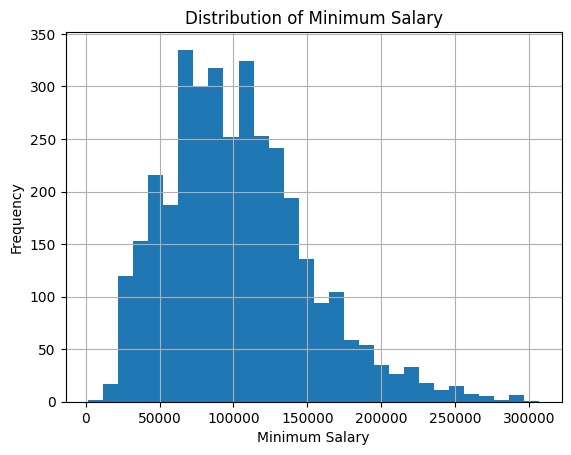

In [27]:
print("Minimum Salary Skewness:", df["Salary_min_usd"].skew())
df["Salary_min_usd"].hist(bins=30)
plt.title("Distribution of Minimum Salary")
plt.xlabel("Minimum Salary")
plt.ylabel("Frequency")
plt.show()


Maximum Salary Skewness: 0.7813360814760044


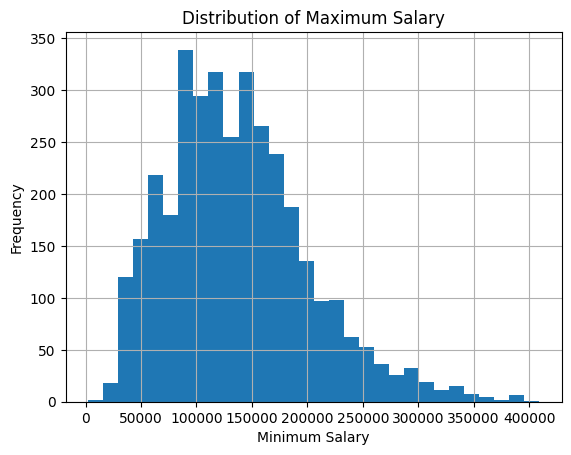

In [28]:
print("Maximum Salary Skewness:", df["Salary_max_usd"].skew())
df["Salary_max_usd"].hist(bins=30)
plt.title("Distribution of Maximum Salary")
plt.xlabel("Minimum Salary")
plt.ylabel("Frequency")
plt.show()


**Skewness Analysis**

The skewness values were 0.7808 for minimum salary and 0.7813 for maximum salary, indicating moderate positive skewness in both distributions. The original salary values were retained without transformation because the project focuses on exploratory analysis and interpretable salary comparisons. Skewness alone did not justify transforming the data

** Stage 3 – EDA and Visualizations**



**1. Univariate Analysis**


**Analysis by Top 10 job roles:**


**Type of Analysis: Descriptive Analysis**

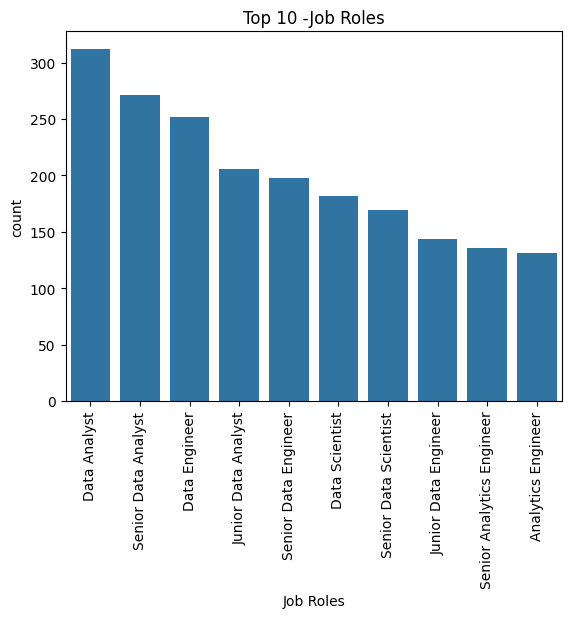

In [29]:
sns.countplot(data=df, x="Title", order=df["Title"].value_counts().head(10).index)
plt.title("Top 10 -Job Roles")
plt.xlabel("Job Roles")
plt.xticks(rotation=90)
plt.show()

**Insights:**

Data Analyst has the highest number of postings among the top 10 job roles.

Senior Data Analyst and Data Engineer are the next most frequently occurring roles.

Data Analyst-related roles appear prominently among the top job postings.

Data Engineer and Data Scientist roles also have significant representation.

**Interpretation:**

The chart represents the top 10 job roles based on the number of job postings in the dataset.

It shows which job roles occur most frequently in the dataset.

Feature: Title
Analysis: Count of job postings
Visualization: Countplot

This analysis shows the relative frequency of different data-related job roles in the dataset. It helps identify which roles are most commonly represented in the collected job postings.

**Analysis by distribution of Seniority**

**Type of Analysis: Descriptive Analysis**

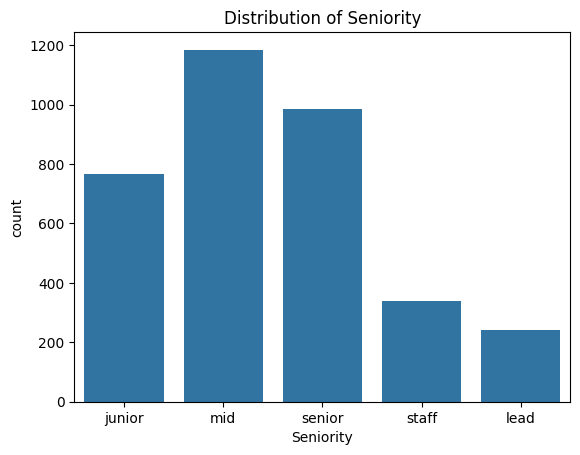

In [30]:
sns.countplot(data=df, x="Seniority")
plt.title("Distribution of Seniority")
plt.xlabel("Seniority")
plt.show()

 **Insights:**

 Mid-level positions have the highest number of postings, with approximately 1,180 postings.

Senior-level positions are the second most represented, with approximately 990 postings.

Junior-level positions account for approximately 760 postings.

Staff and Lead positions have considerably fewer postings compared with junior, mid, and senior positions.

Overall, the dataset contains substantially more mid, senior, and junior-level postings than staff and lead positions.



**Interpretation:**

The chart shows the distribution of job postings across different seniority levels.

It shows how frequently each seniority level occurs in the dataset. Mid-level positions have the highest posting count, followed by senior and junior positions.


Feature: seniority
Analysis: Count of job postings
Visualization: Countplot


This analysis shows the experience-level distribution of the job postings in the dataset. It indicates that mid-level roles are most frequently represented, while staff and lead roles occur less frequently.


**Analysis by distribution of Job Type**

**Type of Analysis: Descriptive Analysis**

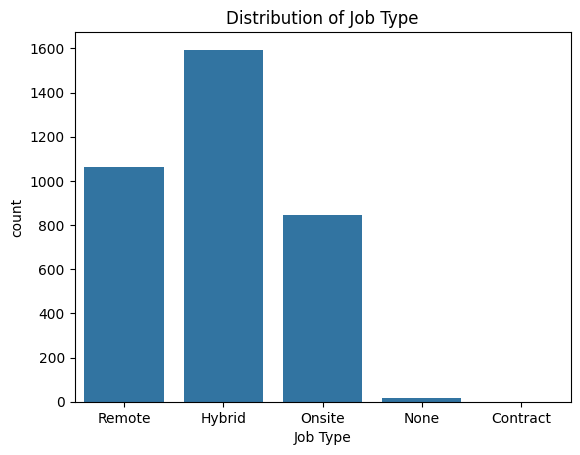

In [31]:
sns.countplot(data=df, x="Job_type")
plt.title("Distribution of Job Type")
plt.xlabel("Job Type")
plt.show()

**Insights:**

Hybrid jobs have the highest number of postings among the different job types.

Remote jobs are the next most frequently occurring job type.

Onsite jobs have fewer postings compared with hybrid and remote jobs.

Hybrid and remote job types together represent a significant portion of the job postings.

**Interpretation:**

The chart represents the distribution of job postings based on job type in the dataset.

It shows how frequently different job types occur in the dataset.

Feature: Job_type

Analysis: Count of job postings

Visualization: Countplot

This analysis shows the relative frequency of different job types in the dataset. It helps identify the work arrangements that are most commonly represented in the collected job postings.

**Analysis by Top 10 Job Posting Location**

**Type of Analysis: Descriptive Analysis**

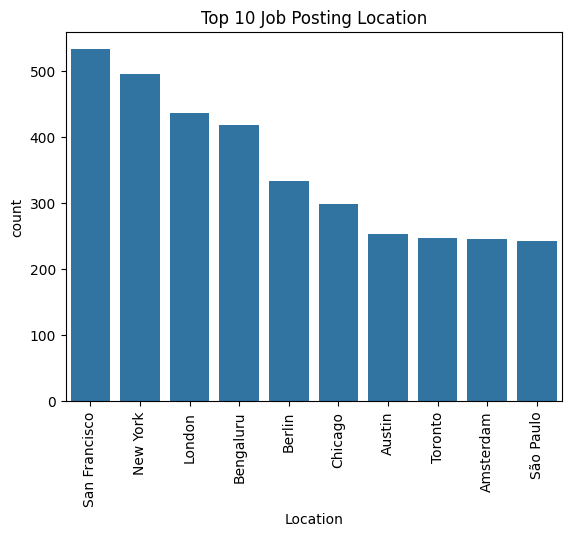

In [32]:
sns.countplot(data=df, x="City", order=df["City"].value_counts().head(10).index)
plt.title("Top 10 Job Posting Location")
plt.xlabel("Location")
plt.xticks(rotation=90)
plt.show()

**Insights:**

San Francisco has the highest number of job postings among the top 10 locations.

New York is the second most frequently occurring job location.

London and Bengaluru also have a high number of job postings.

Berlin and Chicago have moderate representation among the top 10 locations.

Austin, Toronto, Amsterdam, and São Paulo have comparatively fewer postings among the top 10 locations.

**Interpretation:**

The chart represents the top 10 job posting locations based on the number of job postings in the dataset.

It shows which cities occur most frequently in the dataset.

Feature: City
Analysis: Count of job postings
Visualization: Countplot

This analysis shows the relative frequency of job postings across different cities. It helps identify the locations that are most commonly represented in the collected job postings.

**Analysis by Top 10 Countries**

**Type of Analysis: Descriptive Analysis**

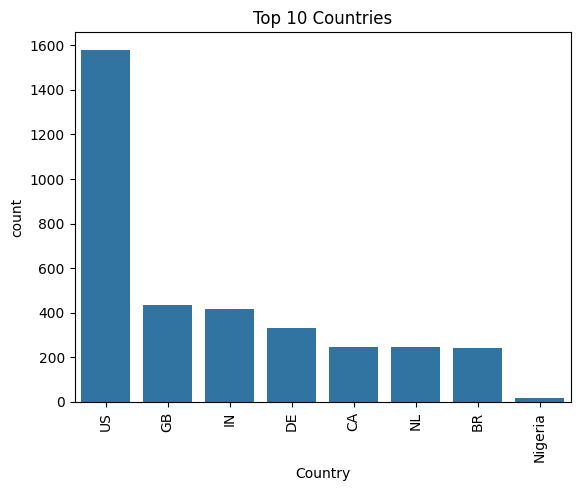

In [33]:
sns.countplot(data=df, x="Country", order=df["Country"].value_counts().head(10).index)
plt.title("Top 10 Countries")
plt.xlabel("Country")
plt.xticks(rotation=90)
plt.show()

**Insights:**

US has the highest number of job postings among the countries shown in the chart.

GB is the second most frequently occurring country.

India has a similar level of representation to GB, followed by Germany.

Canada, Netherlands, and Brazil have comparatively fewer job postings.

Nigeria has the lowest number of postings among the countries shown.

**Interpretation:**

The chart represents the top job posting countries based on the number of job postings in the dataset.

It shows which countries occur most frequently in the dataset.

Feature: Country

Analysis: Count of job postings

Visualization: Countplot

This analysis shows the relative frequency of job postings across different countries. It helps identify the countries that are most commonly represented in the collected job postings.

**2. Bivariate Analysis**

**Analysis: Average Minimum Salary by Seniority**

**Type of Analysis: Diagnostic Analysis**

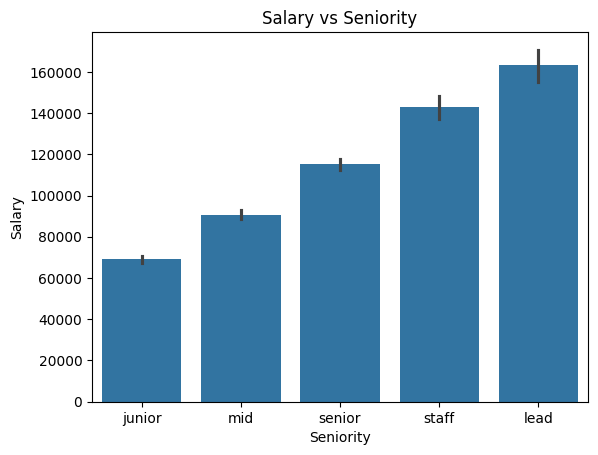

In [34]:
sns.barplot(data=df,x="Seniority",y="Salary_min_usd")
plt.title("Salary vs Seniority")
plt.xlabel("Seniority")
plt.ylabel("Salary")
plt.show()

**Insights:**

Junior positions have the lowest average minimum salary among the seniority levels.

The average minimum salary increases from junior to mid-level and senior positions.

Staff-level positions have a higher average minimum salary than junior, mid, and senior positions.

Lead positions have the highest average minimum salary in the dataset.

Overall, the chart shows an increasing salary pattern as seniority level increases.

**Interpretation:**

The chart represents the average minimum salary across different seniority levels in the dataset.

It shows how the average minimum salary varies across junior, mid, senior, staff, and lead positions.

Features: Seniority, Salary_min_usd
Analysis: Average minimum salary by seniority
Visualization: Barplot

This analysis shows the relationship between seniority level and average minimum salary in the dataset. It helps identify how salary levels vary across different experience levels.

**Analysis: Average Minimum Salary by Job Type**

**Type of Analysis: Diagnostic Analysis**


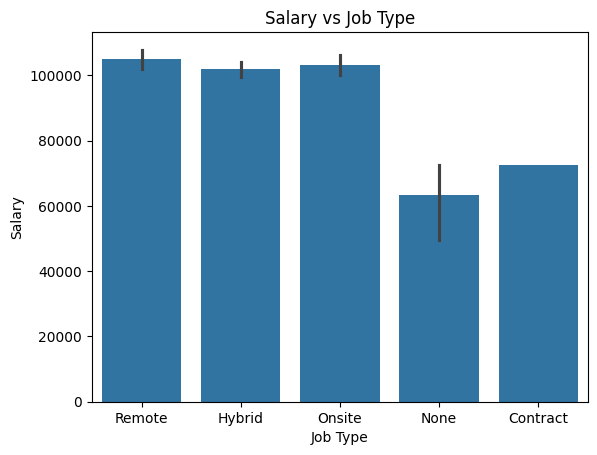

In [35]:
sns.barplot(data=df,x="Job_type",y="Salary_min_usd")
plt.title("Salary vs Job Type")
plt.xlabel("Job Type")
plt.ylabel("Salary")
plt.show()

**Insights:**
Remote jobs have the highest average minimum salary among the job types shown.

Onsite and hybrid jobs also have relatively high average minimum salaries.

The chart shows differences in average minimum salary across the different job types.

**Interpretation:**
The chart represents the average minimum salary across different job types in the dataset.

It shows how the average minimum salary varies across different work arrangements.

**Features**: Job_type, Salary_min_usd

**Analysis**: Average minimum salary by job type

**Visualization**: Barplot

This analysis shows the relationship between job type and average minimum salary in the dataset. It helps identify how salary levels vary across different work arrangements.

**Analysis: Top 10 Job Roles vs Salary**

**Type of Analysis: Diagnostic Analysis**

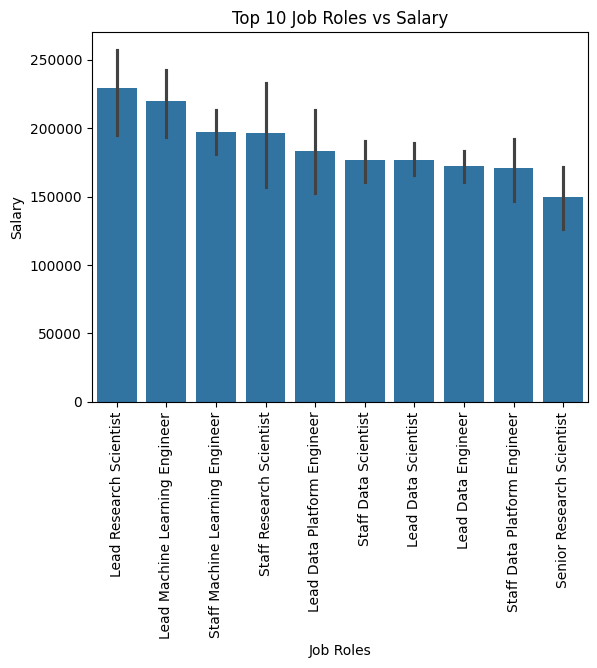

In [36]:
sns.barplot(data=df,x="Title",
            y="Salary_min_usd",
            order=df.groupby("Title")["Salary_min_usd"].mean().sort_values(ascending=False).head(10).index)
plt.xlabel("Job Roles")
plt.ylabel("Salary")
plt.title("Top 10 Job Roles vs Salary")
plt.xticks(rotation=90)
plt.show()

**Insights**:
Lead Research Scientist has the highest average minimum salary among the top 10 job roles shown.

Lead Machine Learning Engineer has the second-highest average minimum salary.

Staff Machine Learning Engineer and Staff Research Scientist also have relatively high average minimum salaries.

Senior Research Scientist has the lowest average minimum salary among the top 10 roles shown.

Overall, the chart shows noticeable differences in average minimum salary across the selected job roles.

**Interpretation**:

The chart represents the average minimum salary for the top 10 job roles in the dataset.
It shows how the average minimum salary varies across different job roles.

**Features:** Title, Salary_min_usd

**Analysis:** Average minimum salary by top 10 job roles

**Visualization:**Barplot

This analysis shows the relationship between job role and average minimum salary in the dataset. It helps identify how salary levels vary across different data-related job roles.

**Analysis: Salary distribution by Seniority**

**Type of Analysis: Diagnostic Analysis**

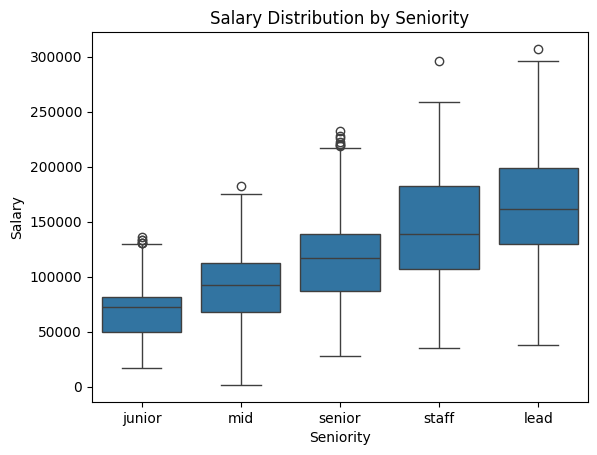

In [37]:
sns.boxplot(data=df,x="Seniority",y="Salary_min_usd")
plt.title("Salary Distribution by Seniority")
plt.xlabel("Seniority")
plt.ylabel("Salary")
plt.show()

**Insights**:

Junior positions have the lowest median salary among the seniority levels.

The median salary increases progressively from junior to mid, senior, staff, and lead positions.

Lead positions have the highest median salary and a relatively wide salary range.

Senior positions show several high-salary outliers above the upper range.


Junior and mid-level positions also contain some salary outliers.
Overall, salary levels and salary ranges tend to increase as the seniority level increases.

**Interpretation:**

The chart represents the distribution of minimum salaries across different seniority levels in the dataset.

It shows how the salary distribution varies across junior, mid, senior, staff, and lead positions, including the median, spread, and potential outliers.

**Features:** Seniority, Salary_min_usd

**Analysis:** Salary distribution by seniority

**Visualization:** Boxplot

This analysis shows the relationship between seniority and salary distribution in the dataset. It helps identify differences in typical salary levels, salary variation, and potential outliers across different seniority levels.

**3.Multi-Variate Analysis**

**Analysis: Salary by Seniority and Job Type**

**Type of Analysis: Diagnostic Analysis**

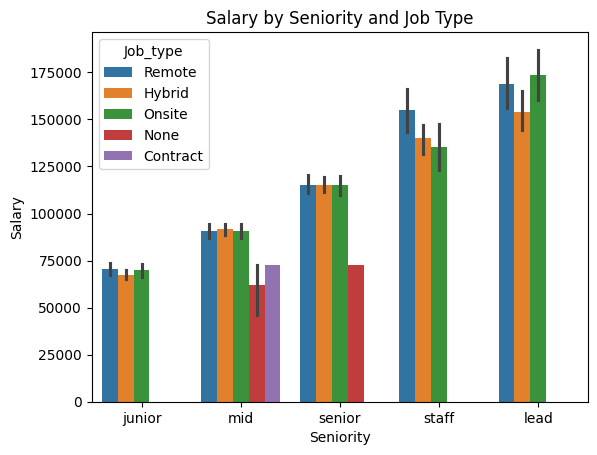

In [38]:
sns.barplot(data=df,x="Seniority",y="Salary_min_usd",hue="Job_type")
plt.title("Salary by Seniority and Job Type")
plt.xlabel("Seniority")
plt.ylabel("Salary")
plt.show()

**Insights:**
- Average salary generally increases from Junior → Mid → Senior → Staff → Lead across job types.
- Junior, Mid, and Senior roles have relatively similar salary levels across Remote, Hybrid, and Onsite.
- For Staff and Lead roles, salary differences between job types become more noticeable.
- Remote has the highest average salary for Staff roles.
- Onsite has the highest average salary for Lead roles.
- The None job type shows lower average salaries, but this represents unspecified work arrangement, so it should not be directly compared with the defined job types.

**Interpretation**:
The chart represents the average minimum salary by seniority and job type.

It shows how salary varies across different seniority levels and work arrangements.

**Feature:** Seniority, Job_type, Salary_min_usd

**Analysis:** Average minimum salary by seniority and job type

**Visualization:** Grouped Barplot  

This analysis shows the relationship between seniority, job type, and average minimum salary, with salary generally increasing as seniority increases.

**Analysis: Job Role, Seniority and Job Count**

**Type of Analysis: Diagnostic Analysis**

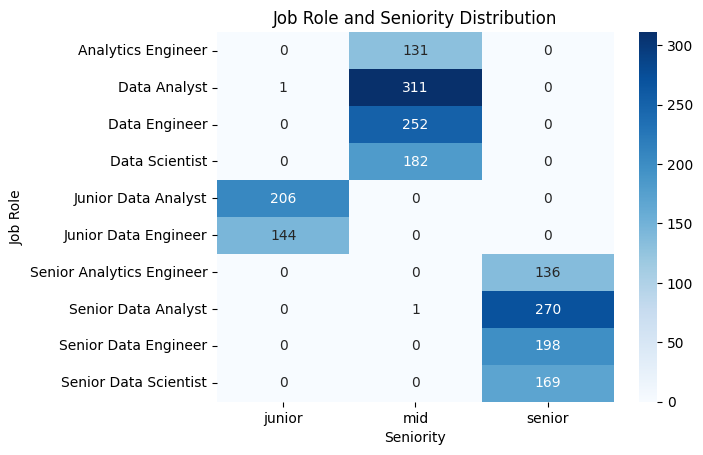

In [39]:
top_roles = df["Title"].value_counts().head(10).index

role_seniority = df[df["Title"].isin(top_roles)].pivot_table(
    index="Title",
    columns="Seniority",
    values="Posting_id",
    aggfunc="count",
    fill_value=0
)

sns.heatmap(role_seniority, annot=True, fmt="d", cmap="Blues")

plt.title("Job Role and Seniority Distribution")
plt.xlabel("Seniority")
plt.ylabel("Job Role")
plt.show()

**Insights:**
- Data Analyst has the highest number of Mid-level postings, with 311.
- Senior Data Analyst has the highest number of Senior-level postings, with 270.
- Data Engineer has 252 Mid-level postings.
- Junior Data Analyst has 206 Junior-level postings.
- Data Scientist has 182 Mid-level postings.
- Senior Data Engineer has 198 Senior-level postings.

**Interpretation:**

The chart represents the distribution of job postings by job role and seniority level.

It shows the number of job postings for different job roles across Junior, Mid, and Senior levels.

**Feature:** Title, Seniority

**Analysis:** Job count by job role and seniority

**Visualization:** Heatmap  

This analysis shows how different job roles are distributed across seniority levels, with Data Analyst and Data Engineer roles having strong representation at the Mid level, while senior-specific roles have higher representation at the Senior level.










**Analysis: Skills, Job Role and Seniority**

**Type of Analysis: Diagnostic Analysis**

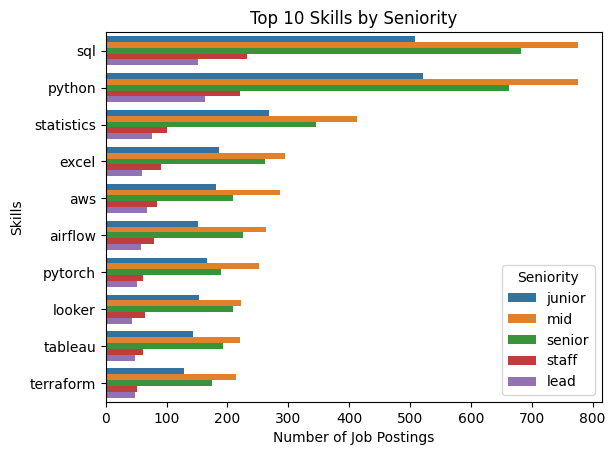

In [40]:
skills = df[["Skills", "Seniority"]].copy()

skills["Skills"] = skills["Skills"].str.split("|")
skills = skills.explode("Skills")

top_skills = skills["Skills"].value_counts().head(10).index

skills = skills[skills["Skills"].isin(top_skills)]

sns.countplot(
    data=skills,
    y="Skills",
    hue="Seniority",
    order=top_skills
)

plt.title("Top 10 Skills by Seniority")
plt.xlabel("Number of Job Postings")
plt.ylabel("Skills")
plt.show()

**Insights**:
- SQL and Python are the most demanded skills across the seniority levels.
- For SQL and Python, Mid-level postings have the highest counts.
- Statistics is the third most demanded skill, with stronger representation at the Mid and Senior levels.
- Excel shows higher demand at the Mid and Senior levels compared with Staff and Lead.
- AWS, Airflow, PyTorch, Looker, Tableau, and Terraform also show demand across multiple seniority levels.
- Across most skills, Mid-level positions have the highest number of postings.

**Interpretation:**
The chart represents the distribution of the top 10 in-demand skills across different seniority levels.

It shows how frequently each skill appears in job postings for Junior, Mid, Senior, Staff, and Lead positions.

**Feature:** Skills, Seniority

**Analysis:** Job count by skill and seniority

**Visualization:** Grouped Barplot  

This analysis shows that SQL and Python are the most in-demand skills, particularly for Mid-level and Senior positions, while the demand for other technical and analytical skills varies across seniority levels.



## **Steps to Download your cleaned data for dashboard creation using Power BI**


In [41]:
df.to_csv("Job_Market.csv", index=False)
from google.colab import files
files.download("Job_Market.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Final Overall Insights:**

1. **Descriptive Analysis** — What does the job market look like?

The analysis shows that the dataset contains 3,518 job postings across 51 unique job roles and 8 countries. Data Analyst, Data Engineer and Data Scientist are among the prominent job roles in the dataset. SQL and Python appear among the most in-demand skills, followed by skills such as Statistics, Excel, AWS and Airflow. Mid-level positions represent the largest seniority group, followed by Senior and Junior positions. The dashboard also shows opportunities across hybrid, remote and onsite work arrangements.

2. **Diagnostic Analysis** — What patterns and relationships can be observed?

Comparing salary with seniority shows that average minimum salary generally increases from Junior to Mid, Senior, Staff and Lead positions. The analysis also highlights differences in job demand across roles, locations and seniority levels. SQL and Python appear across multiple seniority groups, indicating their relevance to different levels of data-related work. These comparisons reveal associations and patterns in the dataset, although they do not establish the causes of salary or demand differences.

3. **Predictive Analysis** — What might happen in the future?

The current project does not include a predictive model, so future job demand cannot be concluded from the dashboard alone. As a possible future extension, historical job-posting data collected consistently over time could be used to forecast demand for specific skills and roles. Such forecasts would need to be tested against actual results before being used for decision-making.

4. **Prescriptive Analysis** — What actions can be recommended?

Based on the observed demand patterns, job seekers can prioritize SQL and Python while developing complementary skills such as Statistics, Excel, Power BI and relevant cloud or data-engineering tools, depending on their target roles. Beginners can focus on foundational skills and projects, while experienced professionals can explore advanced technical skills and higher-seniority opportunities. Employers and training providers can use the findings to review skill requirements and plan learning programmes. Before making salary or work-arrangement decisions, users should also consider missing values, differences between data sources and the limitations of the available sample.



# **Conclusion**

This project demonstrates how Python and Power BI can be used together to clean, explore and visualize job-market data. The Python analysis identifies important patterns, while the interactive Power BI dashboard allows users to investigate job roles, skills, seniority, locations, salaries and work arrangements through filters, drill-down and drill-through. The findings provide a useful overview of the observed data-job market and can support informed career-planning and skill-development decisions. Predictive forecasting remains a potential future enhancement.